# Matplotlib

<svg xmlns="http://www.w3.org/2000/svg" width="480" height="200" viewBox="0 0 600 250">
<rect x="60" y="20" width="480" height="200" rx="14" fill="#ffffff" stroke="#9aa0a6" stroke-width="3"/>
<line x1="110" y1="190" x2="510" y2="190" stroke="#1b1b1b" stroke-width="3"/>
<line x1="110" y1="190" x2="110" y2="45" stroke="#1b1b1b" stroke-width="3"/>
<rect x="130" y="140" width="34" height="50" fill="#00ab0e"/>
<rect x="174" y="110" width="34" height="80" fill="#00ab0e"/>
<rect x="218" y="125" width="34" height="65" fill="#00ab0e"/>
<polyline points="280,160 310,150 340,120 370,70 400,95 430,130 460,140 490,135" fill="none" stroke="#c53030" stroke-width="5" stroke-linejoin="round"/>
<line x1="270" y1="100" x2="500" y2="100" stroke="#9aa0a6" stroke-width="2" stroke-dasharray="8 6"/>
<circle cx="370" cy="70" r="7" fill="#c53030"/>
</svg>

[Chaque question est suivie d'une cellule vide : écrivez-y votre réponse. Utilisez le style `fig, ax = plt.subplots()` de matplotlib et NumPy pour les calculs.]

In [2]:
import matplotlib.pyplot as plt
import numpy as np

## 1. Une première figure

Exécutez la cellule ci-dessous : elle simule les $48$ premières heures d'un patient, une mesure par heure (`t` en heures, `temp` en °C, `hr` en battements par minute).

In [3]:
rng = np.random.default_rng(3)
t = np.arange(48)
fever = 1.6 * np.exp(-(((t - 20) / 7.0) ** 2))
temp = 36.9 + fever + rng.normal(0, 0.12, t.size)
hr = 74 + 14 * fever + rng.normal(0, 3, t.size)

Tracez `temp` contre `t` (`fig, ax = plt.subplots()`, `ax.plot`).
Étiquetez les deux axes, avec leurs unités, et donnez un titre à la figure (`ax.set_xlabel`, `ax.set_ylabel`, `ax.set_title`).

Text(0.5, 1.0, 'Patient P0001')

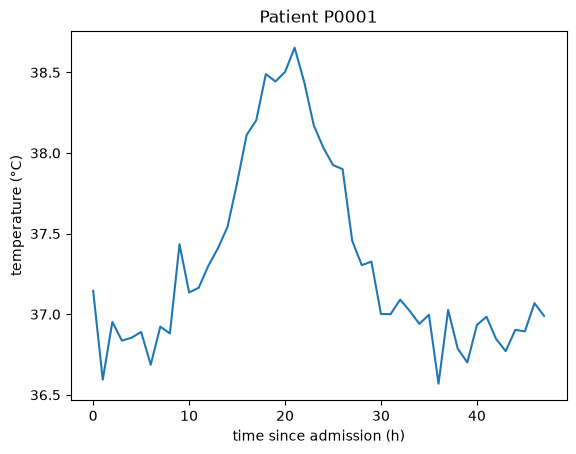

In [4]:
fig, ax = plt.subplots()
ax.plot(t, temp)
ax.set_xlabel("time since admission (h)")
ax.set_ylabel("temperature (°C)")
ax.set_title("Patient P0001")

Refaites le tracé en rouge, avec un point sur chaque mesure (`color`, `marker`).
Ajoutez une ligne horizontale pointillée au seuil de fièvre $38$ °C (`ax.axhline`, `ls="--"`), attribuez à chaque ligne un `label` et affichez la légende (`ax.legend`).

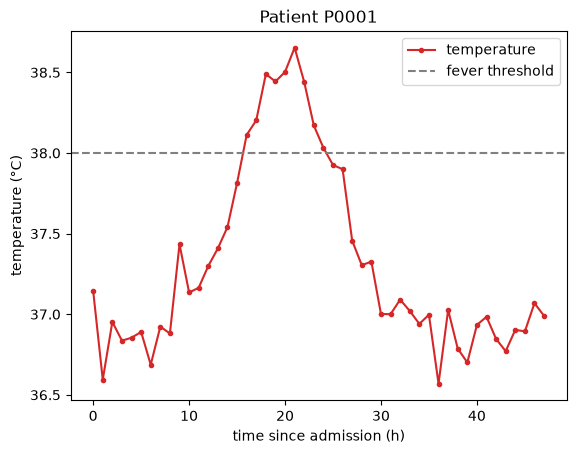

In [5]:
fig, ax = plt.subplots()
ax.plot(t, temp, color="tab:red", marker="o", ms=3, label="temperature")
ax.axhline(38, color="grey", ls="--", label="fever threshold")
ax.set_xlabel("time since admission (h)")
ax.set_ylabel("temperature (°C)")
ax.set_title("Patient P0001")
ax.legend()

Ajoutez la plage normale $36.5$ à $37.5$ °C sous forme de bande vert clair (`ax.fill_between`, `alpha`). Pendant combien d'heures le patient a-t-il été fébrile ? (Répondez avec NumPy, pas en lisant le graphique.)

np.int64(9)

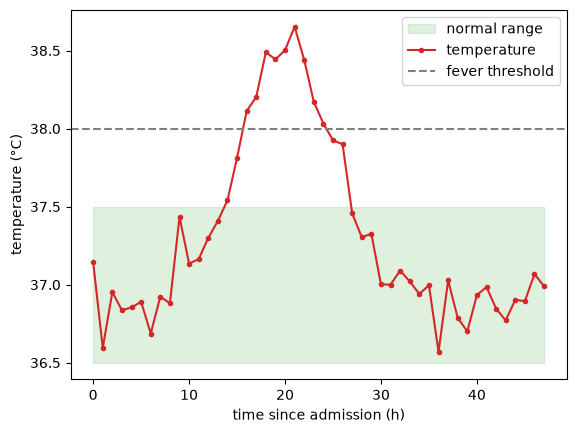

In [6]:
fig, ax = plt.subplots()
ax.fill_between(t, 36.5, 37.5, color="tab:green", alpha=0.15, label="normal range")
ax.plot(t, temp, color="tab:red", marker="o", ms=3, label="temperature")
ax.axhline(38, color="grey", ls="--", label="fever threshold")
ax.set_xlabel("time since admission (h)")
ax.set_ylabel("temperature (°C)")
ax.legend()
(temp >= 38).sum()  # one measurement per hour, so this is a number of hours

## 2. Plusieurs Axes en une seule figure

Tracez la température et la fréquence cardiaque sur deux axes, l'un au-dessus de l'autre, partageant le même axe temporel (`plt.subplots(2, 1, sharex=True)`). Pourquoi est-ce mieux que de tracer les deux courbes dans les mêmes axes ?

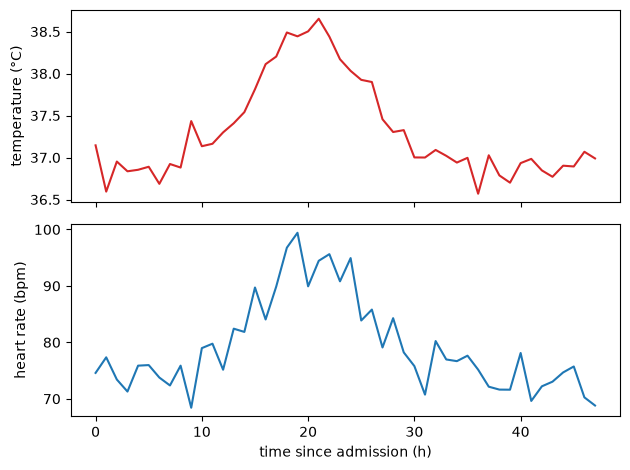

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)
ax1.plot(t, temp, color="tab:red")
ax1.set_ylabel("temperature (°C)")
ax2.plot(t, hr, color="tab:blue")
ax2.set_ylabel("heart rate (bpm)")
ax2.set_xlabel("time since admission (h)")
fig.tight_layout()
# the two measurements have different units and scales: in one Axes, the
# temperature would be a flat line at the bottom of the heart rate plot

Créez une grille $2 \times 3$ d'axes avec `fig, axes = plt.subplots(2, 3)`. Imprimez le type et la forme de `axes`.

(numpy.ndarray, (2, 3))

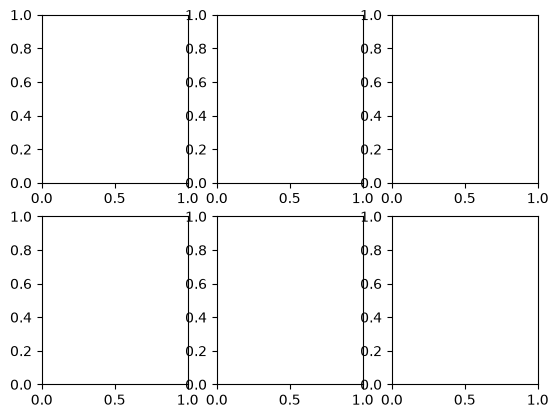

In [8]:
fig, axes = plt.subplots(2, 3)
type(axes), axes.shape

Dans une grille $2 \times 3$, tracez $\sin(k x)$ pour $x \in [0, 2\pi]$ et $k = 1, \dots, 6$, un par axes, avec le titre `"k = 1"`, `"k = 2"`, ... Utilisez une seule boucle sur `axes.flat` (`enumerate`). Terminez par un titre pour la figure entière (`fig.suptitle`) et `fig.tight_layout()`.

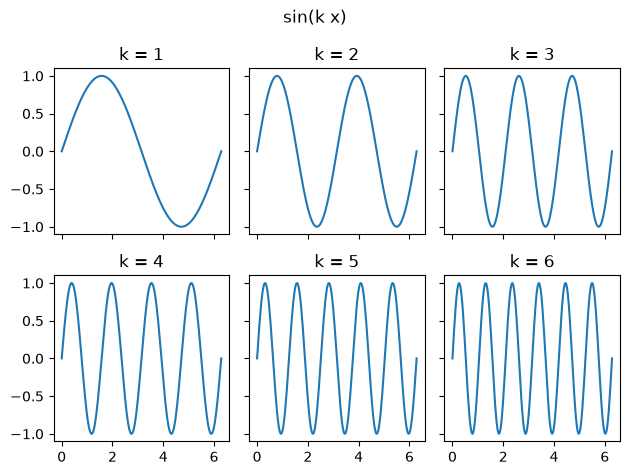

In [9]:
x = np.linspace(0, 2 * np.pi, 200)
fig, axes = plt.subplots(2, 3, sharex=True, sharey=True)
for k, ax in enumerate(axes.flat, start=1):
    ax.plot(x, np.sin(k * x))
    ax.set_title(f"k = {k}")
fig.suptitle("sin(k x)")
fig.tight_layout()

## 3. Un graphique par question

Exécutez la cellule ci-dessous : elle simule une cohorte de $200$ patients (`height` en mètres, `weight` en kilogrammes, `sex` est $0$ pour F et $1$ pour M).

In [10]:
rng = np.random.default_rng(42)
n = 200
sex = rng.integers(0, 2, n)
height = rng.normal(1.63, 0.07, n) + 0.13 * sex
weight = 22 * height**2 + rng.normal(0, 9, n) + 4 * sex
bmi = weight / height**2

Dessinez le poids en fonction de la taille, un point par patient (`ax.scatter`). Étiquetez les axes.

Text(0, 0.5, 'weight (kg)')

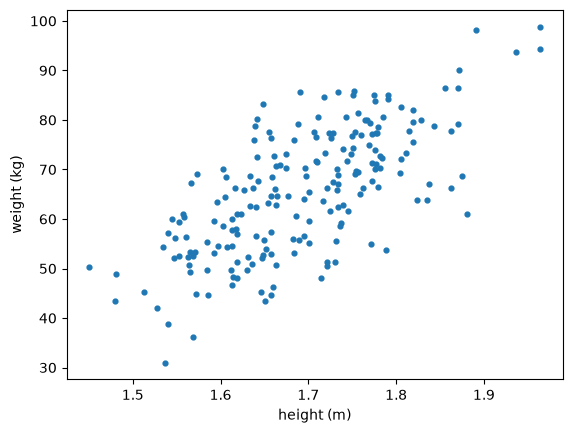

In [11]:
fig, ax = plt.subplots()
ax.scatter(height, weight, s=12)
ax.set_xlabel("height (m)")
ax.set_ylabel("weight (kg)")

Refaites le nuage de points avec une couleur par sexe et une légende.

*Astuce : appelez `ax.scatter` deux fois, une fois par masque booléen, à chaque fois avec un `label`.*

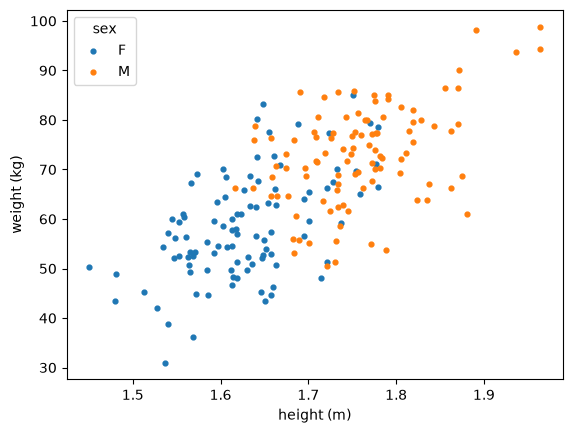

In [12]:
fig, ax = plt.subplots()
for value, name in [(0, "F"), (1, "M")]:
    mask = sex == value
    ax.scatter(height[mask], weight[mask], s=12, label=name)
ax.set_xlabel("height (m)")
ax.set_ylabel("weight (kg)")
ax.legend(title="sex")

Refaites le nuage de points coloré par l'IMC de chaque patient (`c=bmi`, `cmap="viridis"`), et ajoutez une barre de couleur avec son unité (`fig.colorbar(sc, ax=ax, label=...)`, où `sc` est la valeur renvoyée par `ax.scatter`).

Text(0, 0.5, 'weight (kg)')

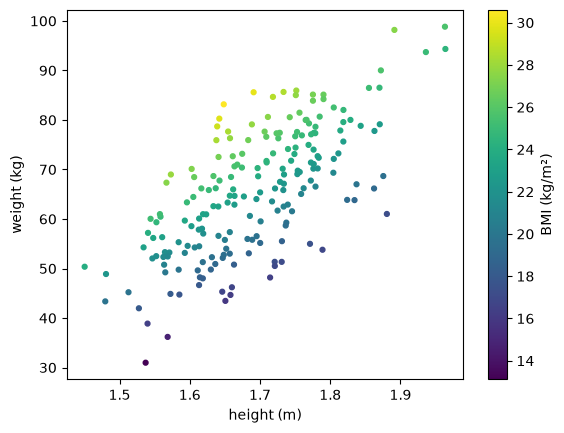

In [13]:
fig, ax = plt.subplots()
sc = ax.scatter(height, weight, c=bmi, cmap="viridis", s=12)
fig.colorbar(sc, ax=ax, label="BMI (kg/m²)")
ax.set_xlabel("height (m)")
ax.set_ylabel("weight (kg)")

Tracez l'histogramme de l'IMC trois fois, côte à côte, avec `bins=5`, `bins=20` et `bins=100` (`ax.hist`). Lequel garderiez-vous ?

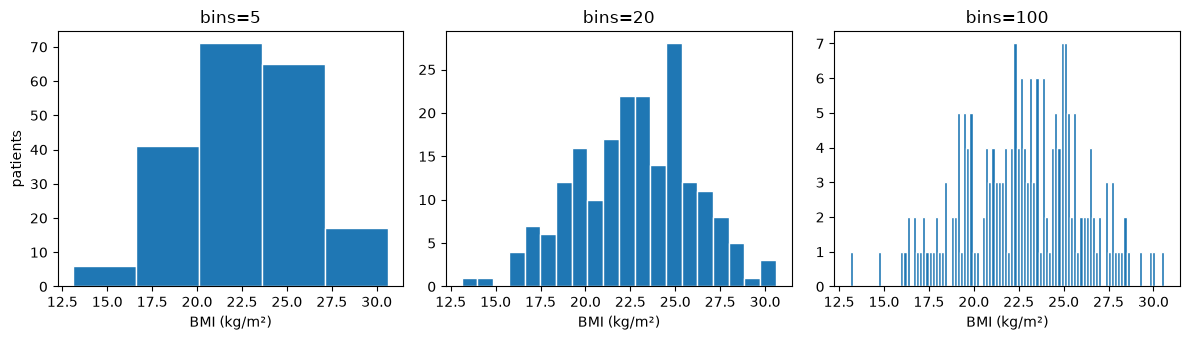

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, bins in zip(axes, [5, 20, 100]):
    ax.hist(bmi, bins=bins, edgecolor="white")
    ax.set_title(f"bins={bins}")
    ax.set_xlabel("BMI (kg/m²)")
axes[0].set_ylabel("patients")
fig.tight_layout()
# 5 bins hide the shape, 100 bins show mostly noise: around 20 is a good compromise

Dessinez l'histogramme de l'IMC avec une barre par unité d'IMC (`bins=np.arange(12, 33)`) et des lignes verticales à $18.5$, $25$ et $30$ (`ax.axvline`).

Text(0, 0.5, 'patients')

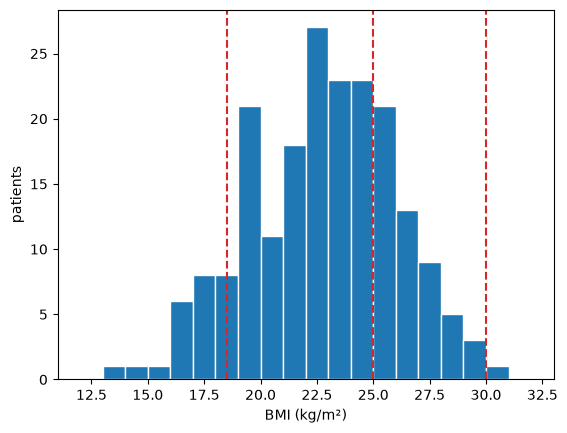

In [15]:
fig, ax = plt.subplots()
ax.hist(bmi, bins=np.arange(12, 33), edgecolor="white")
for cut in [18.5, 25, 30]:
    ax.axvline(cut, color="tab:red", ls="--")
ax.set_xlabel("BMI (kg/m²)")
ax.set_ylabel("patients")

Comptez les patients dans chaque catégorie d'IMC (poids insuffisant, normal, surpoids, obèse : `np.digitize`, `np.bincount`) et affichez les décomptes sous forme de graphique à barres (`ax.bar`), avec le décompte écrit sur chaque barre (`ax.bar_label`).

Text(0, 0.5, 'patients')

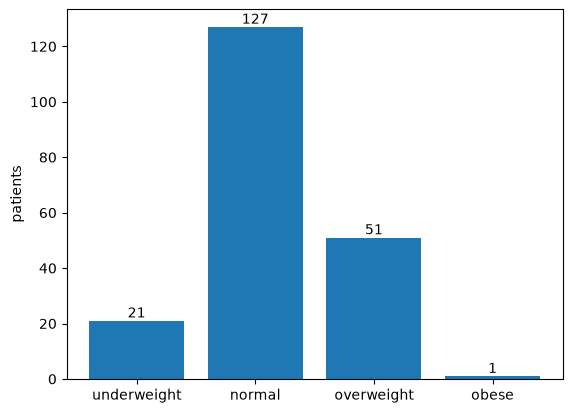

In [16]:
counts = np.bincount(np.digitize(bmi, [18.5, 25, 30]), minlength=4)
fig, ax = plt.subplots()
bars = ax.bar(["underweight", "normal", "overweight", "obese"], counts)
ax.bar_label(bars)
ax.set_ylabel("patients")

Comparez l'IMC des femmes et des hommes avec un boxplot (`ax.boxplot([...], tick_labels=[...])`). Que montrent la ligne dans la boîte, la boîte, les moustaches et les cercles ?

Text(0, 0.5, 'BMI (kg/m²)')

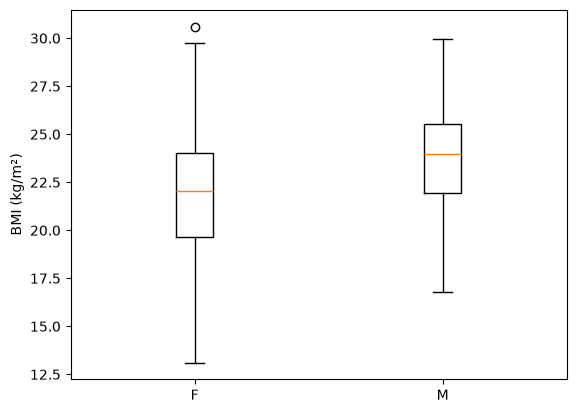

In [17]:
fig, ax = plt.subplots()
ax.boxplot([bmi[sex == 0], bmi[sex == 1]], tick_labels=["F", "M"])
ax.set_ylabel("BMI (kg/m²)")
# line: median; box: from the first to the third quartile (the middle 50 %);
# whiskers: the range of the values within 1.5 box lengths; circles: outliers

## 4. Images

Construisez un tableau $200 \times 200$ `z`, avec $z = e^{-(x^2 + y^2)}$ sur la grille $x, y \in [-2, 2]$ (`np.linspace`, `np.meshgrid`). Affichez-le avec `ax.imshow` et ajoutez une barre de couleurs.

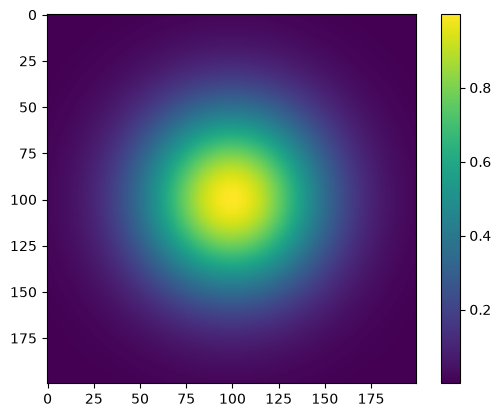

In [18]:
x = np.linspace(-2, 2, 200)
xx, yy = np.meshgrid(x, x)
z = np.exp(-(xx**2 + yy**2))
fig, ax = plt.subplots()
im = ax.imshow(z)
fig.colorbar(im, ax=ax)

Affichez à nouveau `z`, trois fois côte à côte, avec `cmap="gray"`, `cmap="viridis"` et `cmap="jet"`. Lequel montre des arêtes qui ne figurent pas dans les données ?

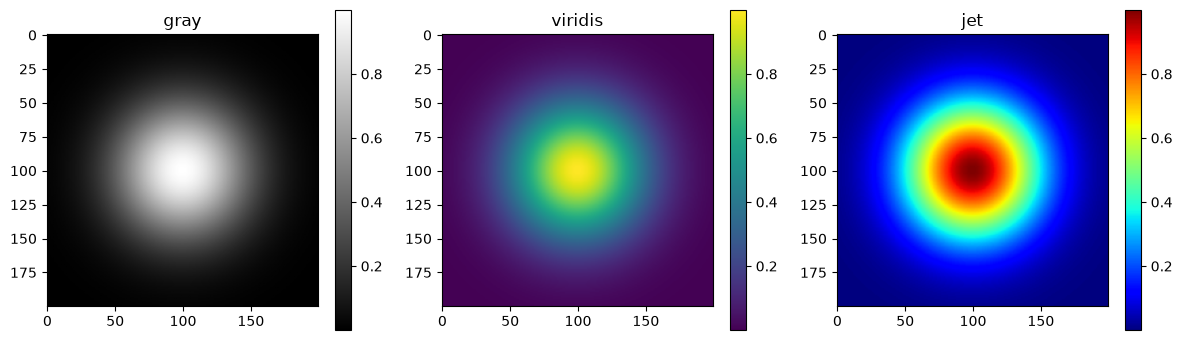

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, cmap in zip(axes, ["gray", "viridis", "jet"]):
    im = ax.imshow(z, cmap=cmap)
    fig.colorbar(im, ax=ax)
    ax.set_title(cmap)
fig.tight_layout()
# jet: the bright yellow and cyan rings look like edges, but z is perfectly smooth

Afficher `z` avec `vmin=0.5` et `vmax=1` : qu'arrive-t-il aux valeurs en dessous de $0.5$ ? Affichez ensuite uniquement les $100 \times 100$ pixels centraux (tranchage).

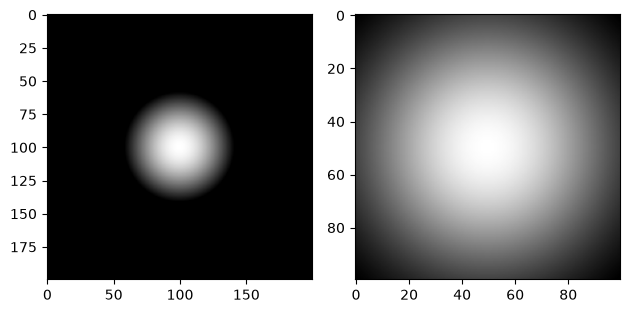

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(z, cmap="gray", vmin=0.5, vmax=1)  # everything below 0.5 is black
ax2.imshow(z[50:150, 50:150], cmap="gray")
fig.tight_layout()

## 5. Sauvegarde

Recréez la figure de température de la question 1 et enregistrez-la deux fois : sous `temperature.png` avec `dpi=200` et sous `temperature.pdf` (`fig.savefig`). Vérifiez que les deux fichiers existent (`Path(...).exists()`, de `pathlib`).

(True, True)

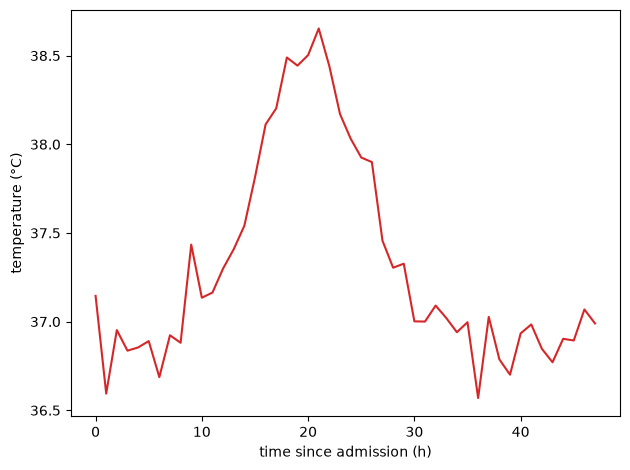

In [21]:
from pathlib import Path

fig, ax = plt.subplots()
ax.plot(t, temp, color="tab:red")
ax.set_xlabel("time since admission (h)")
ax.set_ylabel("temperature (°C)")
fig.tight_layout()
fig.savefig("temperature.png", dpi=200)
fig.savefig("temperature.pdf")
Path("temperature.png").exists(), Path("temperature.pdf").exists()

## 6. Mini cas d'usage : l'export ward

Récupérez d'abord les données : ouvrez [`patients.csv`](https://github.com/MICS-Lab/MS_SanteNum2026/blob/master/Programming01/data/patients.csv) sur GitHub, cliquez sur *Raw* ([lien direct](https://raw.githubusercontent.com/MICS-Lab/MS_SanteNum2026/master/Programming01/data/patients.csv)), sélectionnez tout (`Ctrl+A`), copiez, et collez dans un nouveau fichier texte nommé `patients.csv` sur votre PC. C'est un export synthétique d'un service de $240$ patients, le même pour tout le monde.

Puis mettez dans `path`, dans la cellule ci-dessous, l'endroit où vous avez enregistré le fichier, par exemple `"C:/Users/moi/Documents/patients.csv"` ou `"/home/moi/Documents/patients.csv"` (un chemin relatif à ce notebook fonctionne aussi). La cellule doit afficher `True` ; si elle affiche `False`, le chemin est faux.

La cellule lit ensuite le fichier dans des tableaux NumPy. Un âge manquant devient `np.nan`.

In [22]:
import csv
from pathlib import Path

path = Path("../data/patients.csv")  # à adapter à l'endroit où vous avez enregistré le fichier
print(path.exists())

with open(path) as f:
    rows = list(csv.DictReader(f))

age = np.array([float(r["age"]) if r["age"] else np.nan for r in rows])
los = np.array([float(r["los_days"]) for r in rows])
ward = np.array([r["ward"] for r in rows])
outcome = np.array([r["outcome"] for r in rows])
len(rows), rows[0]

(240,
 {'patient_id': 'P0001',
  'age': '66',
  'sex': 'F',
  'ward': 'ICU',
  'admission': '2024-04-21',
  'los_days': '6.4',
  'outcome': 'transferred'})

Tracez l'histogramme des âges. Combien d’âges manquent et comment les avez-vous laissés de côté ?

*Indice : `np.isnan`.*

np.int64(8)

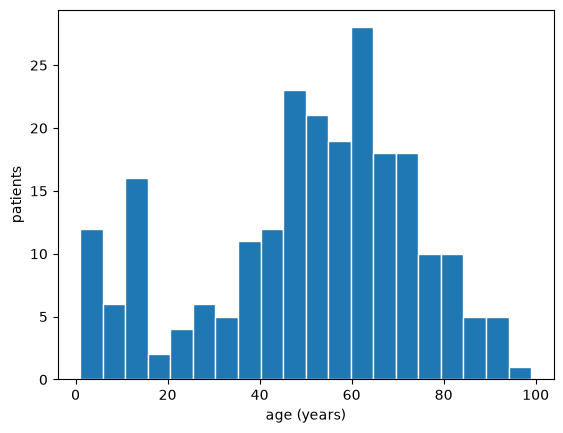

In [23]:
missing = np.isnan(age)
fig, ax = plt.subplots()
ax.hist(age[~missing], bins=20, edgecolor="white")
ax.set_xlabel("age (years)")
ax.set_ylabel("patients")
missing.sum()

Dessinez un diagramme à barres du nombre de patients par service, triés du plus grand service au plus petit.

*Indice : `np.unique(ward, return_counts=True)`, puis `np.argsort`.*

Text(0, 0.5, 'patients')

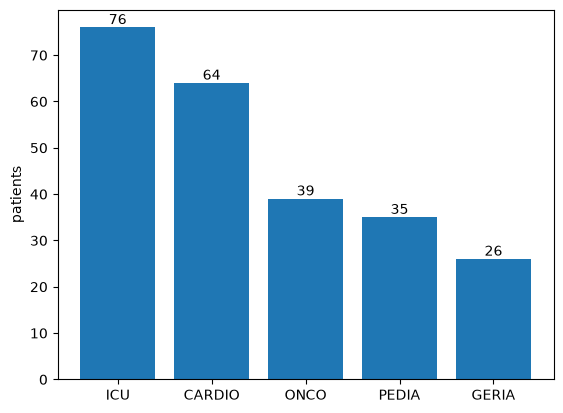

In [24]:
names, counts = np.unique(ward, return_counts=True)
order = np.argsort(counts)[::-1]
fig, ax = plt.subplots()
bars = ax.bar(names[order], counts[order])
ax.bar_label(bars)
ax.set_ylabel("patients")

Comparez la durée du séjour entre les services avec un boxplot. Quel service a le séjour médian le plus long ?

np.str_('ICU')

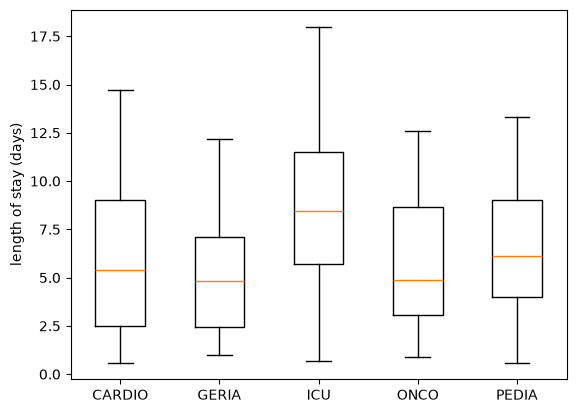

In [25]:
fig, ax = plt.subplots()
ax.boxplot([los[ward == w] for w in names], tick_labels=names)
ax.set_ylabel("length of stay (days)")
names[np.argmax([np.median(los[ward == w]) for w in names])]

Dessinez la durée du séjour en fonction de l'âge, avec une couleur par résultat et une légende.

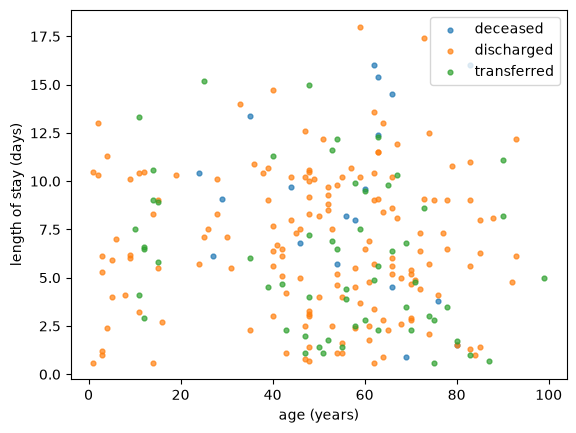

In [26]:
fig, ax = plt.subplots()
for o in np.unique(outcome):
    mask = outcome == o
    ax.scatter(age[mask], los[mask], s=12, alpha=0.7, label=o)
ax.set_xlabel("age (years)")
ax.set_ylabel("length of stay (days)")
ax.legend()

Rassemblez les quatre graphiques précédents en une seule figure $2 \times 2$, avec un titre pour la figure entière, et enregistrez-la sous `ward_report.png`.

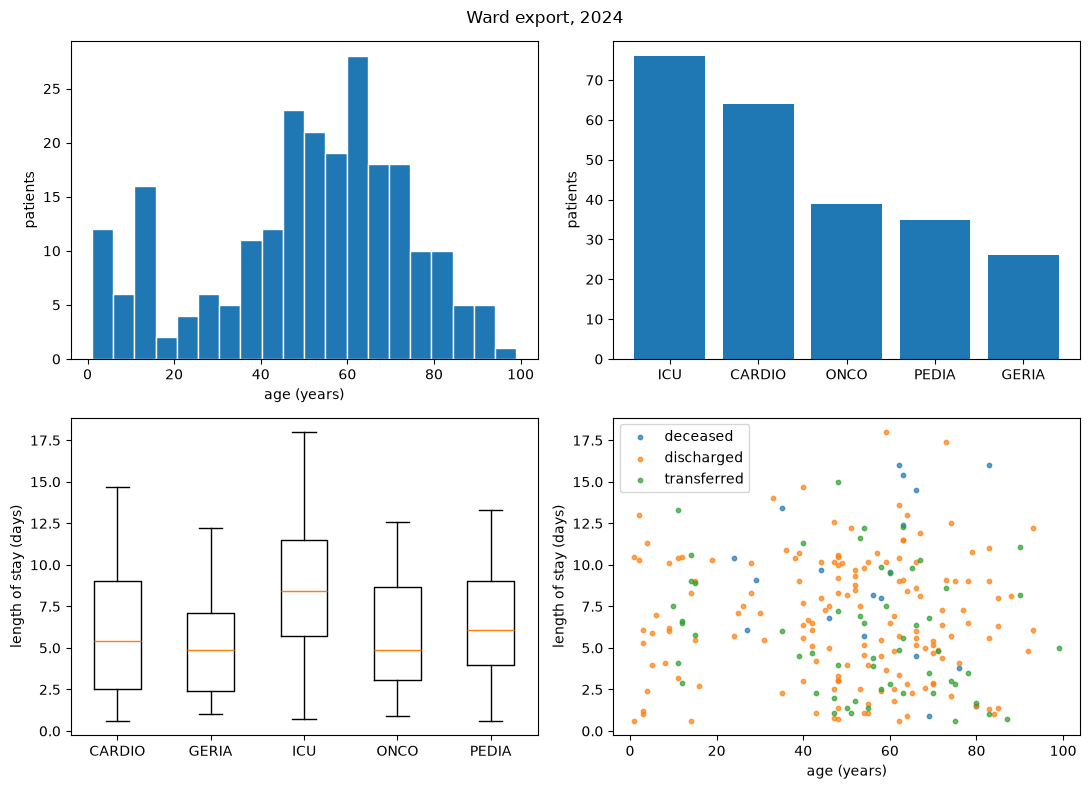

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
a, b, c, d = axes.flat

a.hist(age[~missing], bins=20, edgecolor="white")
a.set_xlabel("age (years)")
a.set_ylabel("patients")

b.bar(names[order], counts[order])
b.set_ylabel("patients")

c.boxplot([los[ward == w] for w in names], tick_labels=names)
c.set_ylabel("length of stay (days)")

for o in np.unique(outcome):
    mask = outcome == o
    d.scatter(age[mask], los[mask], s=10, alpha=0.7, label=o)
d.set_xlabel("age (years)")
d.set_ylabel("length of stay (days)")
d.legend()

fig.suptitle("Ward export, 2024")
fig.tight_layout()
fig.savefig("ward_report.png", dpi=200)